In [2]:
import os
os.chdir('/home/hedi/HSCNG/')
import numpy as np
from astropy.io import fits
from astropy.coordinates import SkyCoord
from astropy.wcs import WCS
from astropy import units as u
import matplotlib.pyplot as plt
import pprint
import pymaster as nmt
from hsc_utils import stats_code
from hsc_utils import map_utils

demonstration of reading the file.

In [3]:
field = 'GAMA09H'
Npatch = 23
i = 0
tomo_bin = 1

In [4]:
f = fits.open(f'results/hscy3_kappa_chopped_{field}_{i}.fits')
# f = fits.open('data/real/hscy3_shape_chopped_VVDS_0.fits')
dat = f[0].data
mask = fits.getdata(f'results/hscy3_mask_chopped_{field}_{i}.fits', 0)
w = WCS(f[0].header)

In [5]:
ny, nx = dat.shape

flatgrid = map_utils.FlatClass(wcs=w, nx=nx, ny=ny)

In [6]:
ra_p, dec_p = flatgrid.pix2pos(np.arange(flatgrid.get_npix()))

ra = ra_p.reshape(dat.shape)
dec = dec_p.reshape(dat.shape)

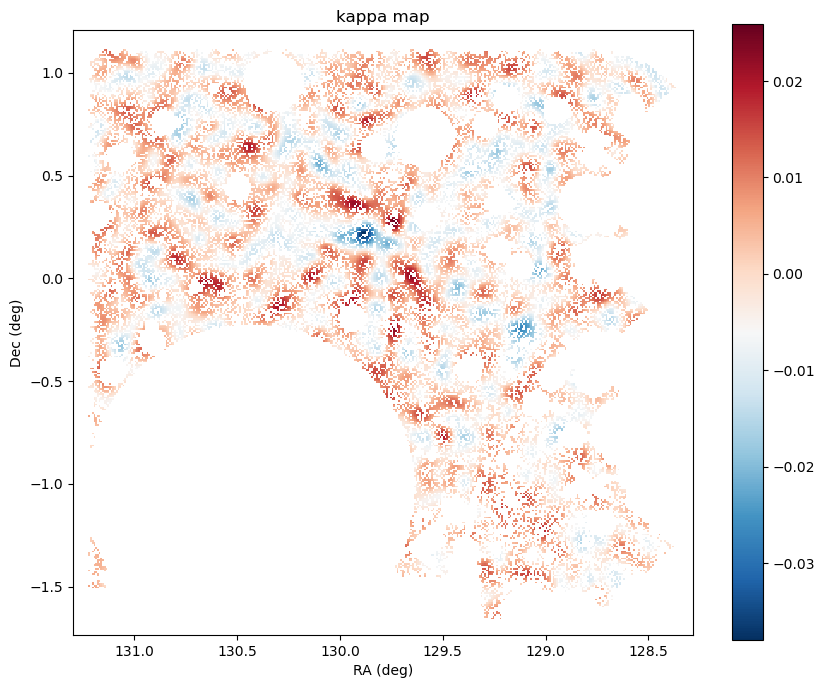

In [7]:
masked = dat.copy()
masked[mask.reshape(ny, nx) == 0] = np.nan
fig, ax = plt.subplots(figsize=(10, 8))
pcm = ax.pcolormesh(ra, dec, masked, cmap='RdBu_r', shading='auto')
cbar = fig.colorbar(pcm, ax=ax)
ax.set_xlabel('RA (deg)')
ax.set_ylabel('Dec (deg)')
ax.set_title('kappa map')
ax.set_aspect('equal', adjustable='box')
# RA often plotted increasing to the left — enable if desired
ax.invert_xaxis()
plt.show()

In [8]:
Cls = np.loadtxt(f'results/hscy3_shape_chopped_{field}_{i}_Cl.txt')

In [9]:
ls, EE, BB, EB = Cls

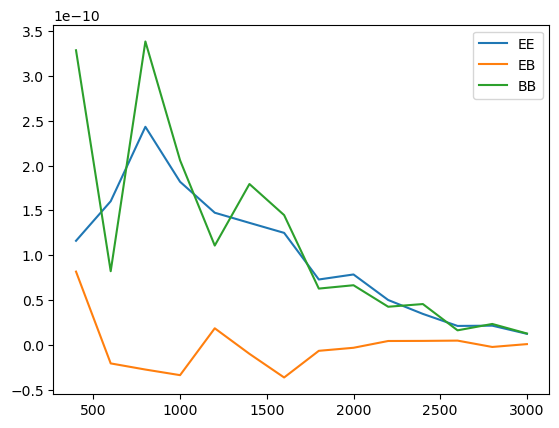

In [10]:
plt.plot(ls, EE, label='EE')
plt.plot(ls, EB, label='EB')
plt.plot(ls, BB, label='BB')

plt.legend()

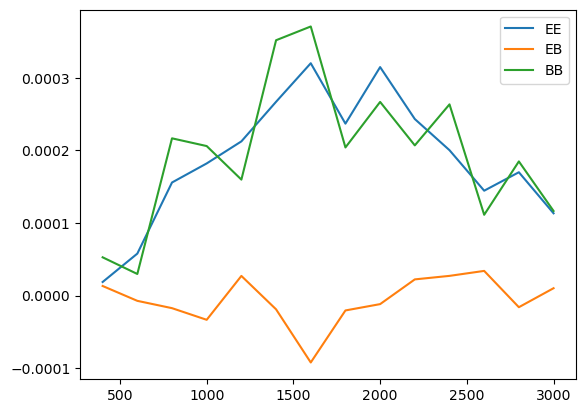

In [11]:
plt.plot(ls, EE*ls*(ls+1), label='EE')
plt.plot(ls, EB*ls*(ls+1), label='EB')
plt.plot(ls, BB*ls*(ls+1), label='BB')

plt.legend()

plot for the large field

In [10]:
field = 'GAMA09H'
Npatch = 23

grids = []
maps = []
masks = []

for i in range(Npatch):
    with fits.open(f'results/hscy3_kappa_chopped_{field}_{i}.fits') as f:
    # f = fits.open('data/real/hscy3_shape_chopped_VVDS_0.fits')
        dat = f[0].data
        w = WCS(f[0].header)
    mask = fits.getdata(f'results/hscy3_mask_chopped_{field}_{i}.fits', 0)

    ny, nx = dat.shape

    maps.append(dat)
    masks.append(mask.reshape(ny, nx))
    grids.append(map_utils.FlatClass(wcs=w, nx=nx, ny=ny))

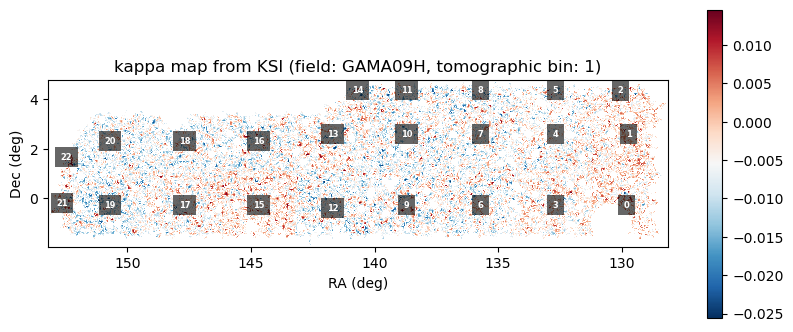

In [11]:
fig, ax = plt.subplots(figsize=(10, 4))

for p, (flatgrid, dat, mask) in enumerate(zip(grids, maps, masks)):
    ra_p, dec_p = flatgrid.pix2pos(np.arange(flatgrid.get_npix()))

    ra_grid = ra_p.reshape(dat.shape)
    dec_grid = dec_p.reshape(dat.shape)

    masked = dat.copy()
    masked[mask == 0] = np.nan

    pcm = ax.pcolormesh(ra_grid, dec_grid, masked, cmap='RdBu_r', shading='auto')

    # patch center from WCS CRVAL (RA, Dec) and label with patch number
    crval = flatgrid.wcs.wcs.crval  # [RA_center, Dec_center]
    ax.text(crval[0], crval[1], str(p),
            color='white', fontsize=6, weight='bold',
            ha='center', va='center',
            bbox=dict(facecolor='black', alpha=0.6, edgecolor='none'),
            zorder=10)

cbar = fig.colorbar(pcm, ax=ax)
ax.set_xlabel('RA (deg)')
ax.set_ylabel('Dec (deg)')
ax.set_title(f'kappa map from KSI (field: {field}, tomographic bin: {tomo_bin})')
ax.set_aspect('equal', adjustable='box')

ax.invert_xaxis()
plt.show()